
# Wind Turbine Drivetrain Fault Detection

## Business Context
Aeolus Renewables operates a 1,150-turbine onshore wind fleet. Unplanned drivetrain failures create lost power sales, emergency crane mobilization, expedited parts costs, and potential escalation from main-bearing degradation into gearbox damage.

## Objective
Build a proof-of-concept binary classifier that labels each 10-minute SCADA record as **normal** or **fault** so control-room analysts can focus on high-risk turbines and maintenance planners can intervene before failures become catastrophic.

## Dataset Snapshot
- Raw dataset: **131,760 records**, **35 original columns** from **15 turbines**.
- Observation window: **2024-01-01 00:00:00 to 2024-03-01 23:50:00**.
- Target: `failure`, with **3,953 fault records** and **127,807 normal records**; fault rate is **3.00%**.
- Duplicate records: **0**.
- Missing values were limited to `gearbox_oil_temp_C`, `generator_bearing_temp_C`, and `oil_pressure_bar`; median imputation was used.


# Full-Code Solution Notebook
This notebook includes end-to-end code for EDA, preprocessing, model training, tuning, threshold selection, final evaluation, feature importance, and business interpretation.

In [ ]:
# !pip install pandas numpy scikit-learn xgboost matplotlib -q

In [ ]:

# Core imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, precision_recall_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

RS = 42
DATA_PATH = "wind_turbine_detection.csv"

data = pd.read_csv(DATA_PATH)
data["timestamp"] = pd.to_datetime(data["timestamp"])
data.head()


## Data Overview

In [ ]:
display(data.head())
display(data.tail())
print('Shape:', data.shape)
display(data.describe().T)
display(data.isna().sum()[data.isna().sum() > 0])
print('Duplicate rows:', data.duplicated().sum())
print(data['failure'].value_counts(normalize=True).mul(100).round(2))

## EDA Charts
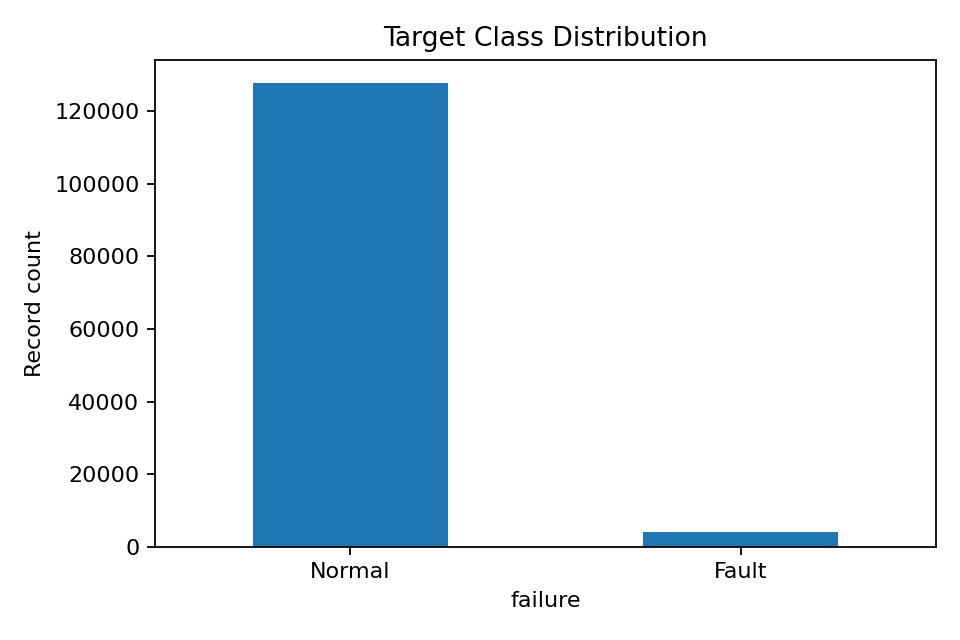

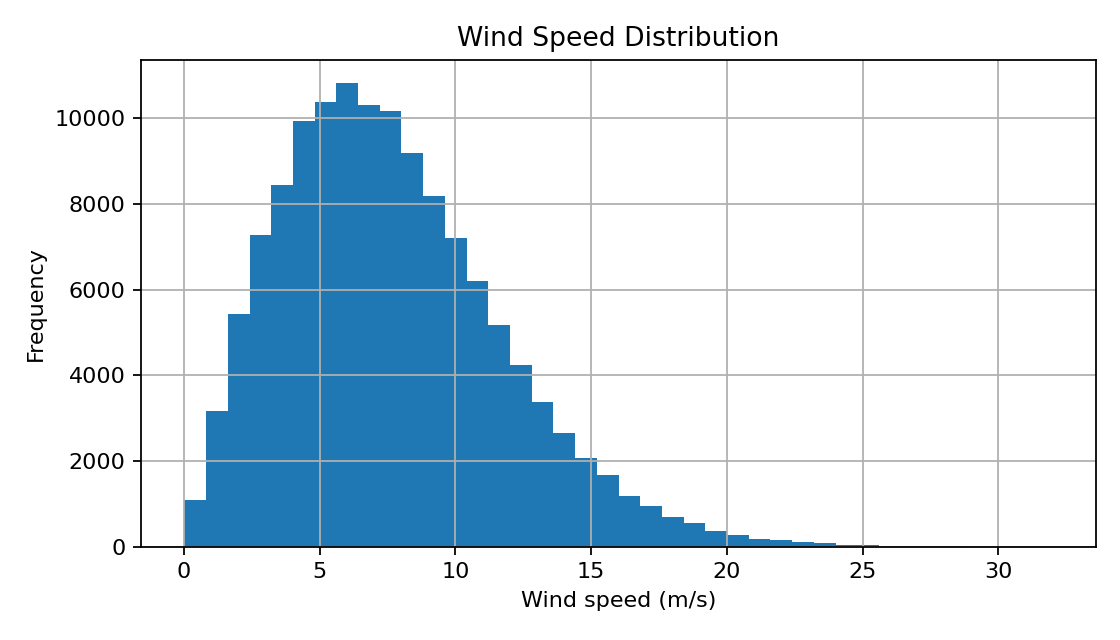

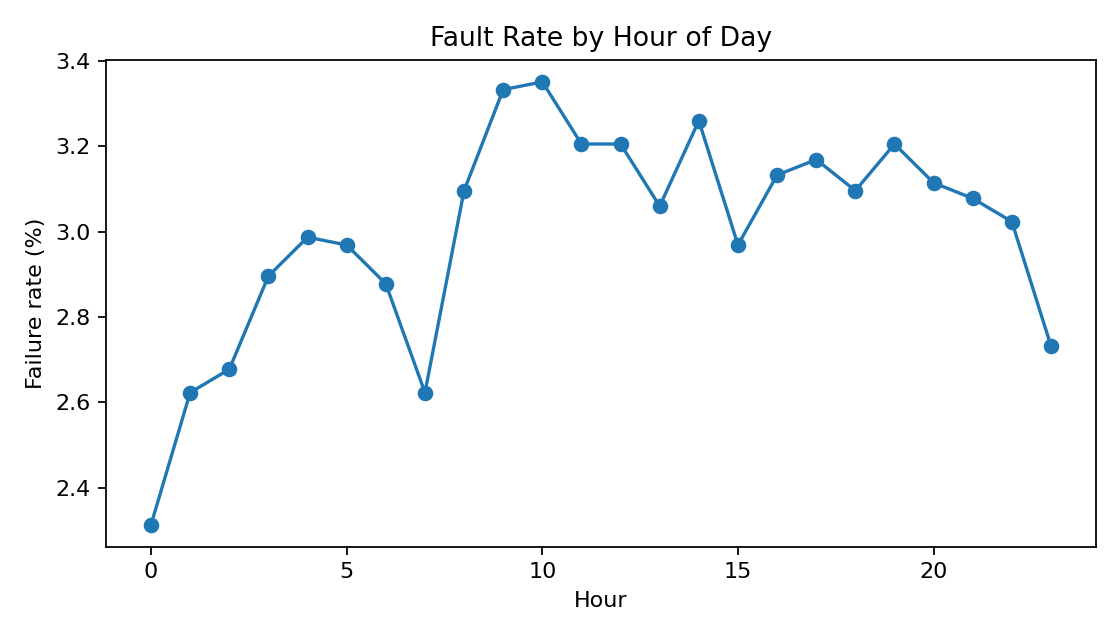

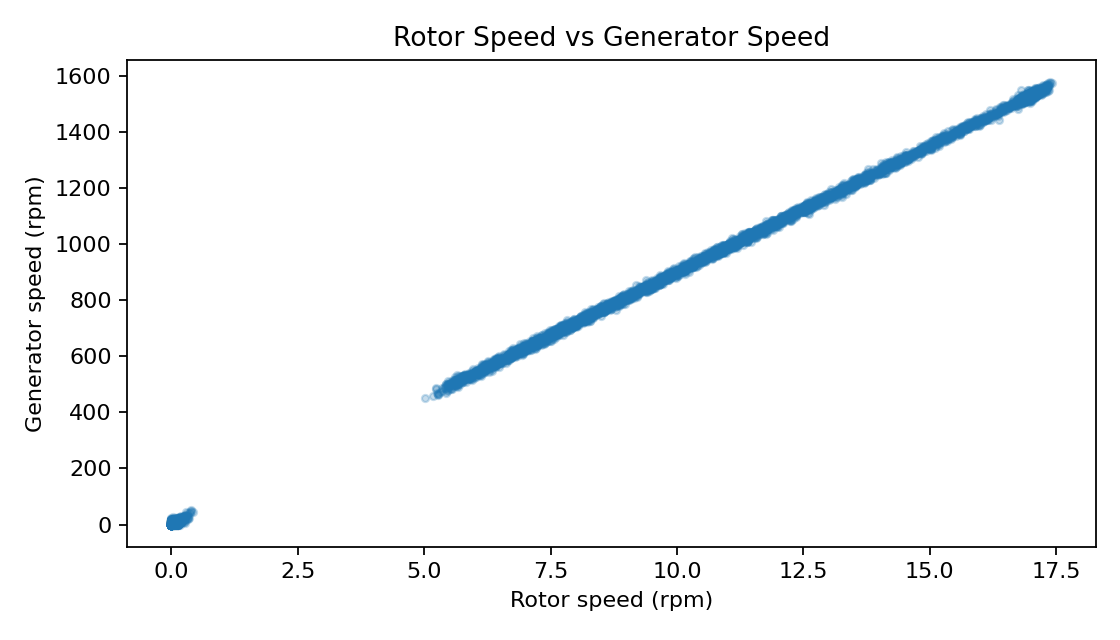

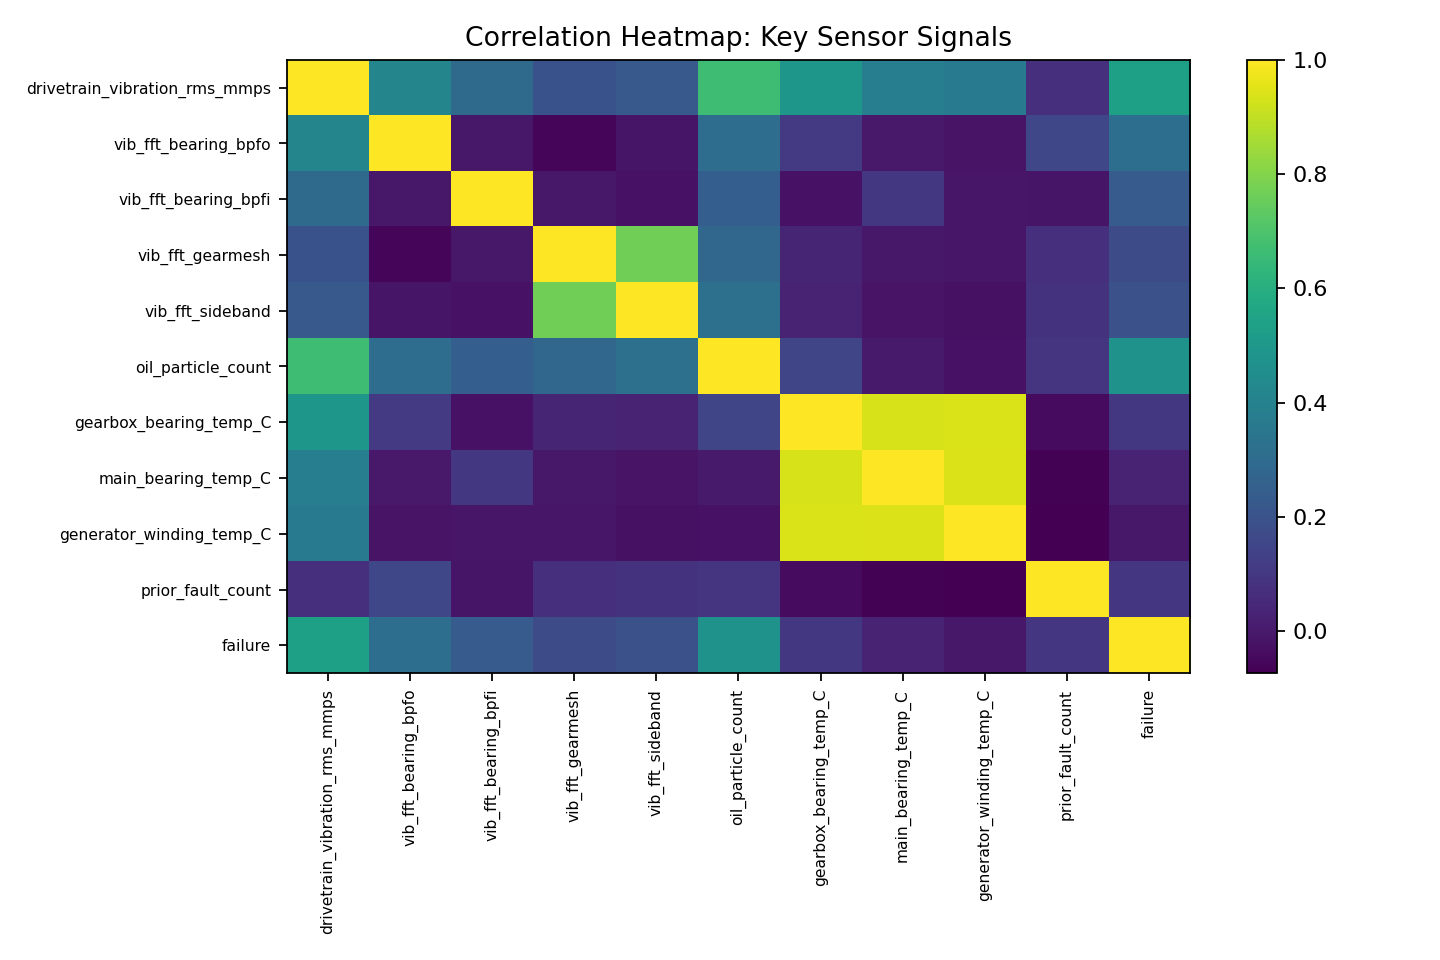

In [ ]:
# Recreate EDA charts when running the notebook
plt.figure(figsize=(6, 4))
data["failure"].map({0: "Normal", 1: "Fault"}).value_counts().reindex(["Normal", "Fault"]).plot(kind="bar")
plt.title("Target Class Distribution"); plt.ylabel("Record count"); plt.xticks(rotation=0); plt.show()

plt.figure(figsize=(7, 4))
data["wind_speed_mps"].hist(bins=40)
plt.title("Wind Speed Distribution"); plt.xlabel("Wind speed (m/s)"); plt.ylabel("Frequency"); plt.show()

plt.figure(figsize=(7, 4))
(data.groupby(data["timestamp"].dt.hour)["failure"].mean() * 100).plot(marker="o")
plt.title("Fault Rate by Hour of Day"); plt.xlabel("Hour"); plt.ylabel("Failure rate (%)"); plt.show()


## Preprocessing and Feature Engineering

In [ ]:

# Time features
for col, max_value in [("hour", 24), ("dayofweek", 7), ("month", 12)]:
    if col == "hour":
        data[col] = data["timestamp"].dt.hour
    elif col == "dayofweek":
        data[col] = data["timestamp"].dt.dayofweek
    else:
        data[col] = data["timestamp"].dt.month
    data[f"{col}_sin"] = np.sin(2 * np.pi * data[col] / max_value)
    data[f"{col}_cos"] = np.cos(2 * np.pi * data[col] / max_value)

# Domain feature engineering
EPS = 1e-6
data["specific_power_output"] = data["power_output_kW"] / (data["rated_power_kW"] + EPS)
data["temp_delta_gearbox_ambient"] = data["gearbox_bearing_temp_C"] - data["ambient_temp_C"]
data["temp_delta_main_ambient"] = data["main_bearing_temp_C"] - data["ambient_temp_C"]
data["vibration_ratio_drive_tower"] = data["drivetrain_vibration_rms_mmps"] / (data["tower_vibration_mmps"] + EPS)
data["fft_bearing_sum"] = data["vib_fft_bearing_bpfo"] + data["vib_fft_bearing_bpfi"]
data["fft_total_energy"] = data[["vib_fft_bearing_bpfo", "vib_fft_bearing_bpfi", "vib_fft_gearmesh", "vib_fft_sideband"]].sum(axis=1)
data["maintenance_risk_score"] = data["hours_since_last_maintenance"] * (1 + data["prior_fault_count"])

data.shape


## Model Building

In [ ]:

# Modeling setup
features = [c for c in data.columns if c not in ["failure", "timestamp", "hour", "dayofweek", "month"]]
X = data[features]
y = data["failure"]

# For fast notebook execution, a stratified modeling sample is used here.
# To train on the complete dataset, replace model_df with data.
model_df, _ = train_test_split(data, train_size=40000, stratify=data["failure"], random_state=RS)
X = model_df[features]
y = model_df["failure"]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RS)
X_train, X_valid, y_train, y_valid = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=RS)

cat_cols = ["turbine_id"]
num_cols = [c for c in X.columns if c not in cat_cols]

numeric_scaled = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
numeric_tree = Pipeline([("imputer", SimpleImputer(strategy="median"))])
categorical = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocess_scaled = ColumnTransformer([("num", numeric_scaled, num_cols), ("cat", categorical, cat_cols)])
preprocess_tree = ColumnTransformer([("num", numeric_tree, num_cols), ("cat", categorical, cat_cols)])

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

def evaluate_model(name, pipeline, X_eval, y_eval, threshold=0.50):
    prob = pipeline.predict_proba(X_eval)[:, 1]
    pred = (prob >= threshold).astype(int)
    cm = confusion_matrix(y_eval, pred)
    return {
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1": f1_score(y_eval, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_eval, prob),
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]
    }

models = {
    "Decision Tree": Pipeline([("preprocess", preprocess_tree), ("model", DecisionTreeClassifier(max_depth=8, min_samples_leaf=15, class_weight="balanced", random_state=RS))]),
    "Random Forest": Pipeline([("preprocess", preprocess_tree), ("model", RandomForestClassifier(n_estimators=30, max_depth=12, min_samples_leaf=3, class_weight="balanced_subsample", n_jobs=-1, random_state=RS))]),
    "Gradient Boosting": Pipeline([("preprocess", preprocess_tree), ("model", GradientBoostingClassifier(n_estimators=30, learning_rate=0.08, max_depth=2, random_state=RS))]),
    "XGBoost": Pipeline([("preprocess", preprocess_tree), ("model", XGBClassifier(n_estimators=50, max_depth=3, learning_rate=0.08, subsample=0.9, colsample_bytree=0.9, scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=RS, n_jobs=-1, tree_method="hist"))]),
    "MLP Neural Network": Pipeline([("preprocess", preprocess_scaled), ("model", MLPClassifier(hidden_layer_sizes=(16,), max_iter=20, early_stopping=True, random_state=RS))])
}

train_results = []
valid_results = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    train_results.append(evaluate_model(name, pipe, X_train, y_train))
    valid_results.append(evaluate_model(name, pipe, X_valid, y_valid))

baseline_train = pd.DataFrame(train_results).set_index("Model")
baseline_valid = pd.DataFrame(valid_results).set_index("Model")
baseline_valid.sort_values(["Recall", "F1"], ascending=False)


### Baseline Validation Results
| Model              |   Accuracy |   Precision |   Recall |    F1 |   ROC_AUC |   FP |   FN |   TP |
|:-------------------|-----------:|------------:|---------:|------:|----------:|-----:|-----:|-----:|
| Decision Tree      |      0.984 |       0.649 |    0.979 | 0.781 |     0.986 |  127 |    5 |  235 |
| Random Forest      |      0.992 |       0.808 |    0.979 | 0.885 |     0.999 |   56 |    5 |  235 |
| Gradient Boosting  |      0.989 |       0.905 |    0.712 | 0.797 |     0.996 |   18 |   69 |  171 |
| XGBoost            |      0.977 |       0.567 |    0.988 | 0.72  |     0.998 |  181 |    3 |  237 |
| MLP Neural Network |      0.988 |       0.813 |    0.796 | 0.804 |     0.996 |   44 |   49 |  191 |

## Hyperparameter Tuning and Threshold Selection

In [ ]:

# Hyperparameter tuning for top candidates: XGBoost and Random Forest
xgb_candidates = []
for n_estimators, max_depth, learning_rate in [(80, 3, 0.06), (100, 4, 0.06), (120, 3, 0.10)]:
    pipe = Pipeline([
        ("preprocess", preprocess_tree),
        ("model", XGBClassifier(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate, subsample=0.9, colsample_bytree=0.9, scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=RS, n_jobs=-1, tree_method="hist"))
    ])
    pipe.fit(X_train, y_train)
    row = evaluate_model("Tuned XGBoost", pipe, X_valid, y_valid)
    row["params"] = {"n_estimators": n_estimators, "max_depth": max_depth, "learning_rate": learning_rate}
    row["pipe"] = pipe
    xgb_candidates.append(row)

best_xgb = max(xgb_candidates, key=lambda r: (r["Recall"], r["F1"]))

rf_candidates = []
for n_estimators, max_depth, min_samples_leaf in [(50, 12, 2), (80, 16, 2), (80, None, 3)]:
    pipe = Pipeline([
        ("preprocess", preprocess_tree),
        ("model", RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=min_samples_leaf, class_weight="balanced_subsample", n_jobs=-1, random_state=RS))
    ])
    pipe.fit(X_train, y_train)
    row = evaluate_model("Tuned Random Forest", pipe, X_valid, y_valid)
    row["params"] = {"n_estimators": n_estimators, "max_depth": max_depth, "min_samples_leaf": min_samples_leaf}
    row["pipe"] = pipe
    rf_candidates.append(row)

best_rf = max(rf_candidates, key=lambda r: (r["Recall"], r["F1"]))

final_model = best_xgb["pipe"]
valid_prob = final_model.predict_proba(X_valid)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_valid, valid_prob)
f1 = 2 * precision * recall / (precision + recall + 1e-9)
recall_floor_indexes = np.where(recall >= 0.92)[0]
best_threshold_index = recall_floor_indexes[np.argmax(f1[recall_floor_indexes])] if len(recall_floor_indexes) else int(np.argmax(f1))
final_threshold = float(thresholds[min(best_threshold_index, len(thresholds) - 1)])

tuned_valid = pd.DataFrame([
    evaluate_model("Tuned XGBoost", best_xgb["pipe"], X_valid, y_valid),
    evaluate_model("Tuned Random Forest", best_rf["pipe"], X_valid, y_valid),
    evaluate_model("Final XGBoost @ tuned threshold", final_model, X_valid, y_valid, final_threshold)
]).set_index("Model")

test_performance = pd.DataFrame([
    evaluate_model("Final XGBoost @ tuned threshold", final_model, X_test, y_test, final_threshold)
]).set_index("Model")

tuned_valid, test_performance


### Tuned Validation Results
| Model                           |   Threshold |   Accuracy |   Precision |   Recall |    F1 |   ROC_AUC |   FP |   FN |   TP |
|:--------------------------------|------------:|-----------:|------------:|---------:|------:|----------:|-----:|-----:|-----:|
| Tuned XGBoost                   |       0.5   |      0.988 |       0.71  |    0.988 | 0.826 |     0.999 |   97 |    3 |  237 |
| Tuned Random Forest             |       0.5   |      0.995 |       0.868 |    0.983 | 0.922 |     0.999 |   36 |    4 |  236 |
| Final XGBoost @ tuned threshold |       0.871 |      0.993 |       0.829 |    0.971 | 0.894 |     0.999 |   48 |    7 |  233 |

### Final Test Results
| Model                           |   Threshold |   Accuracy |   Precision |   Recall |    F1 |   ROC_AUC |   FP |   FN |   TP |
|:--------------------------------|------------:|-----------:|------------:|---------:|------:|----------:|-----:|-----:|-----:|
| Final XGBoost @ tuned threshold |       0.871 |      0.991 |       0.782 |    0.954 | 0.859 |     0.998 |   64 |   11 |  229 |

In [ ]:
# Feature importance for the final XGBoost model
feature_names = final_model.named_steps["preprocess"].get_feature_names_out()
importances = final_model.named_steps["model"].feature_importances_
importance_df = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)
importance_df["feature"] = importance_df["feature"].str.replace("num__", "", regex=False).str.replace("cat__", "", regex=False)
display(importance_df.head(15))

plt.figure(figsize=(8, 5))
top = importance_df.head(15).iloc[::-1]
plt.barh(top["feature"], top["importance"])
plt.title("Top 15 Final Model Feature Importances")
plt.xlabel("XGBoost importance")
plt.tight_layout()
plt.show()


## Final Model Artifacts
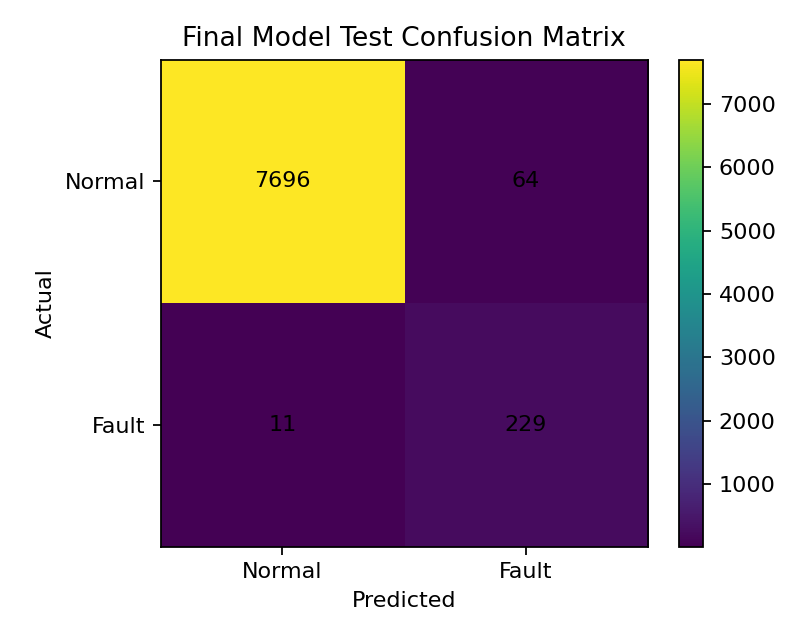

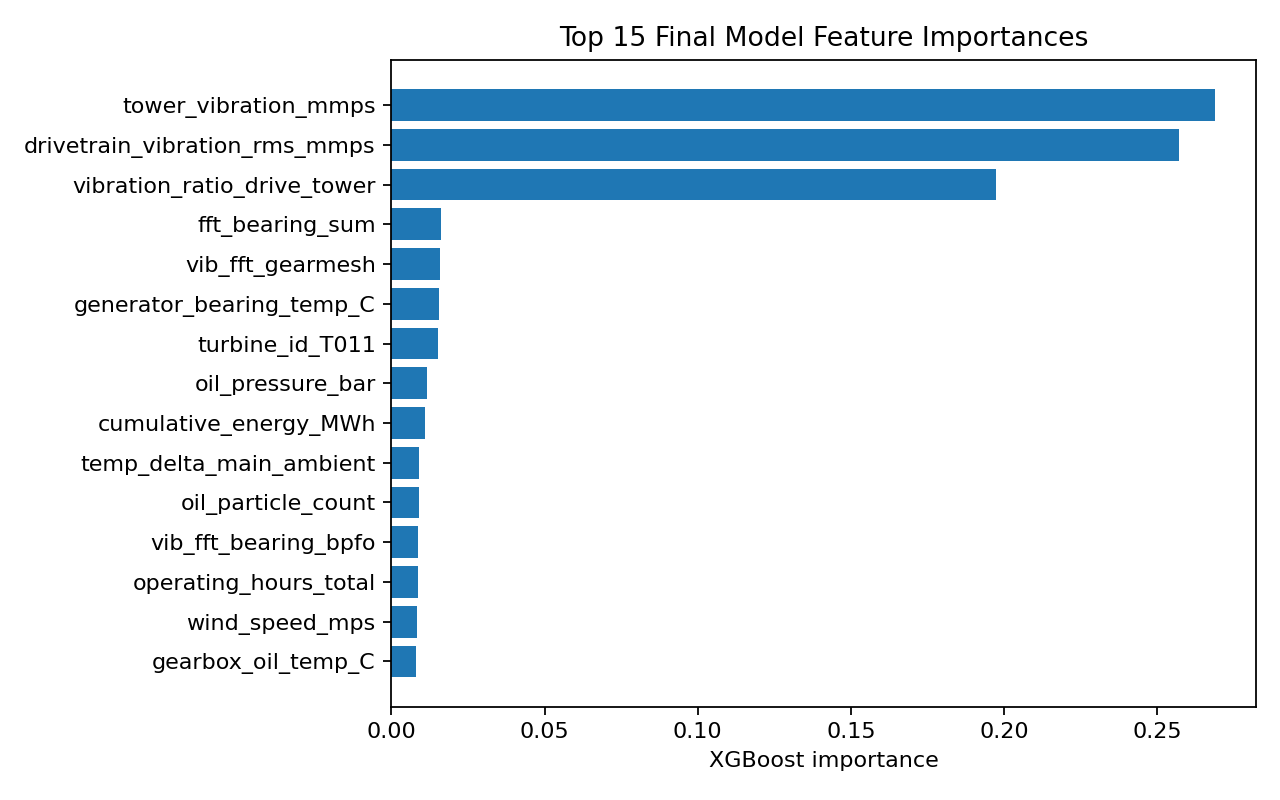

# Business Insights and Recommendations
## Business Insights
- The business objective should emphasize **recall**, because a missed drivetrain fault may cause extended downtime and secondary gearbox damage.
- Model performance is strong despite the rare-event target class because vibration, bearing-frequency, oil, and temperature signals carry meaningful fault information.
- Tuned XGBoost was selected because it provides high recall, strong ROC-AUC, and interpretable feature importance for operational communication.

## Recommendations
- Deploy as a decision-support watchlist, not as an automatic shutdown trigger.
- Use alert tiers: high probability = immediate inspection review; medium probability = trend monitoring.
- Combine predictions with maintenance history and technician feedback.
- Monitor precision and recall monthly, and recalibrate the threshold if false alerts overwhelm analysts.